## chargement du profil des zones

On charge `agg_data/zones_profil.csv`. Le fichier a 29 colonnes, mais seules les **24 features** entrent dans le modèle : les 4 colonnes d'identification servent à interpréter les résultats, et `faible_activite` sert à filtrer.

On garde uniquement les **zones actives** (`faible_activite = 0`) : les zones avec moins d'une course par jour ont des moyennes trop instables pour être segmentées de manière fiable.

**Effet sur les données :** la table des zones actives est en mémoire, et la liste des 24 features est fixée.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
warnings.filterwarnings("ignore")

AGG_DIR = os.path.join(os.getcwd(), "agg_data")
ML_DIR = os.path.join(os.getcwd(), "ml_data")
os.makedirs(ML_DIR, exist_ok=True)

profil = pd.read_csv(os.path.join(AGG_DIR, "zones_profil.csv"))
IDENTIFIANTS = ["zone_id", "nom_zone", "arrondissement", "type_zone"]
FEATURES = [c for c in profil.columns if c not in IDENTIFIANTS + ["faible_activite"]]

actives = profil[profil["faible_activite"] == 0].reset_index(drop=True)
print("Colonnes du fichier :", profil.shape[1])
print("Features utilisées par le modèle :", len(FEATURES))
print("Zones au total :", len(profil), "| zones actives gardées pour le clustering :", len(actives))

Colonnes du fichier : 29
Features utilisées par le modèle : 24
Zones au total : 263 | zones actives gardées pour le clustering : 257


## préparation des données

K-Means calcule des distances : toutes les variables doivent être complètes et sur la même échelle.

1. **Imputation** : s'il reste des valeurs vides (par exemple l'attente VTC dans une zone sans VTC), on les remplace par la **médiane** de la variable. La médiane est robuste aux valeurs extrêmes.
2. **Transformation logarithmique** (`log1p`) sur les variables très asymétriques : `courses_par_jour`, `duree_moy_min`, `distance_moy`, `prix_moy`, `prix_par_mile`, `attente_moy_min`. Sans elle, quelques zones extrêmes (Midtown, les aéroports) écraseraient toutes les autres dans les distances.
3. **Écrêtage** de `croissance_2025` entre −0,9 et +2,0 : une zone presque vide en 2024 peut afficher une croissance énorme qui n'a pas de sens.
4. **Retrait des features constantes** : une variable qui a la même valeur partout n'apporte aucune information au clustering.
5. **Standardisation** (`StandardScaler`) : chaque variable est centrée (moyenne 0) et réduite (écart-type 1), pour qu'aucune ne domine les distances simplement à cause de son unité.

**Effet sur les données :** la matrice `X`, une ligne par zone active et une colonne par feature, toutes centrées et réduites.

In [2]:
X_brut = actives[FEATURES].copy()

print("Valeurs vides avant imputation :")
vides = X_brut.isna().sum()
display(vides[vides > 0].to_frame("nb_vides"))
X_brut = X_brut.fillna(X_brut.median())

A_LOG = ["courses_par_jour", "duree_moy_min", "distance_moy", "prix_moy", "prix_par_mile", "attente_moy_min"]
for c in A_LOG:
    X_brut[c] = np.log1p(X_brut[c])
X_brut["croissance_2025"] = X_brut["croissance_2025"].clip(-0.9, 2.0)

constantes = [c for c in FEATURES if X_brut[c].std() < 1e-9]
print("Features constantes retirées :", constantes)
FEATURES = [c for c in FEATURES if c not in constantes]
X_brut = X_brut[FEATURES]

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_brut), columns=FEATURES)

print("Forme de X :", X.shape)
display(X.describe().T[["mean", "std"]].round(2))

Valeurs vides avant imputation :


,nb_vides
part_especes,1
attente_moy_min,1
part_partage,1
part_pmr,1
part_chauffeur,1


Features constantes retirées : []
Forme de X : (257, 24)


,mean,std
courses_par_jour,-0.0,1.0
part_yellow,0.0,1.0
part_green,0.0,1.0
part_fhv,-0.0,1.0
part_vtc,0.0,1.0
part_weekend,-0.0,1.0
part_nuit,-0.0,1.0
part_matin,-0.0,1.0
part_journee,0.0,1.0
part_fin_aprem,0.0,1.0


## corrélations entre features

On calcule la matrice de corrélation et on liste les paires de variables fortement corrélées (|r| ≥ 0,7). Elle justifie l'ACP : quand plusieurs variables mesurent presque la même chose, elles pèsent plusieurs fois dans les distances de K-Means.

Certaines corrélations sont attendues par construction : les 4 parts de service font 1, les 5 tranches horaires aussi, et la durée, la distance et le prix évoluent ensemble.

**Effet sur les données :** aucun, c'est un diagnostic. On affiche la liste des paires et la carte des corrélations.

Paires de variables fortement corrélées (|r| >= 0.7) : 22


,variable_1,variable_2,correlation
3,part_yellow,taux_pourboire,0.95
1,part_yellow,part_fin_aprem,0.90
4,part_yellow,part_cbd,0.88
12,part_fin_aprem,taux_pourboire,0.85
19,taux_pourboire,part_cbd,0.83
6,part_vtc,taux_pourboire,-0.83
17,distance_moy,prix_moy,0.83
15,duree_moy_min,distance_moy,0.83
21,part_cbd,part_chauffeur,-0.81
16,duree_moy_min,prix_moy,0.81


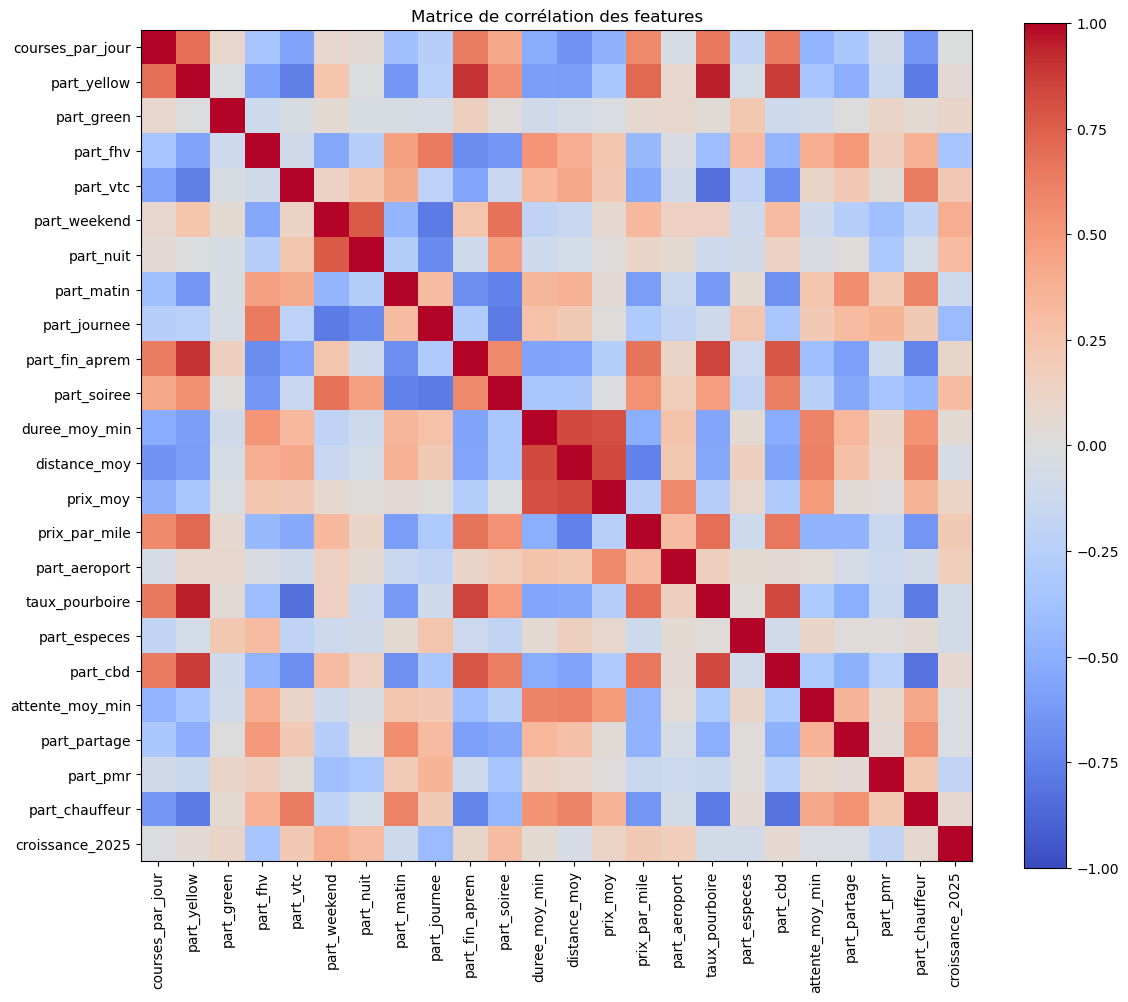

In [3]:
corr = X.corr()
paires = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.7:
            paires.append((FEATURES[i], FEATURES[j], round(r, 2)))

paires = pd.DataFrame(paires, columns=["variable_1", "variable_2", "correlation"])
paires = paires.reindex(paires["correlation"].abs().sort_values(ascending=False).index)
print("Paires de variables fortement corrélées (|r| >= 0.7) :", len(paires))
display(paires)

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(FEATURES)), FEATURES, rotation=90)
plt.yticks(range(len(FEATURES)), FEATURES)
plt.title("Matrice de corrélation des features")
plt.tight_layout()
plt.show()

## ACP complète et choix du nombre de composantes

On applique une ACP avec **toutes** les composantes pour voir combien d'information (de variance) chacune résume. Deux critères classiques aident à choisir combien en garder :
- le **critère de Kaiser** : garder les composantes dont la valeur propre est supérieure à 1, c'est-à-dire celles qui résument plus d'information qu'une variable d'origine seule ;
- le **critère des 80 %** : garder le nombre de composantes nécessaire pour conserver au moins 80 % de la variance totale.

On affiche le tableau des valeurs propres, l'**éboulis** (scree plot) et la courbe de variance cumulée.

**Effet sur les données :** aucun, on décide du nombre de composantes à garder.

,composante,valeur_propre,variance_%,variance_cumulee_%
0,CP1,9.343,38.78,38.78
1,CP2,3.687,15.30,54.08
2,CP3,2.403,9.97,64.06
3,CP4,1.348,5.60,69.65
4,CP5,1.251,5.19,74.84
5,CP6,1.023,4.25,79.09
6,CP7,0.858,3.56,82.65
7,CP8,0.759,3.15,85.80
8,CP9,0.706,2.93,88.73
9,CP10,0.545,2.26,91.00


Critère de Kaiser (valeur propre > 1) : 6 composantes
Critère des 80 % de variance expliquée : 7 composantes


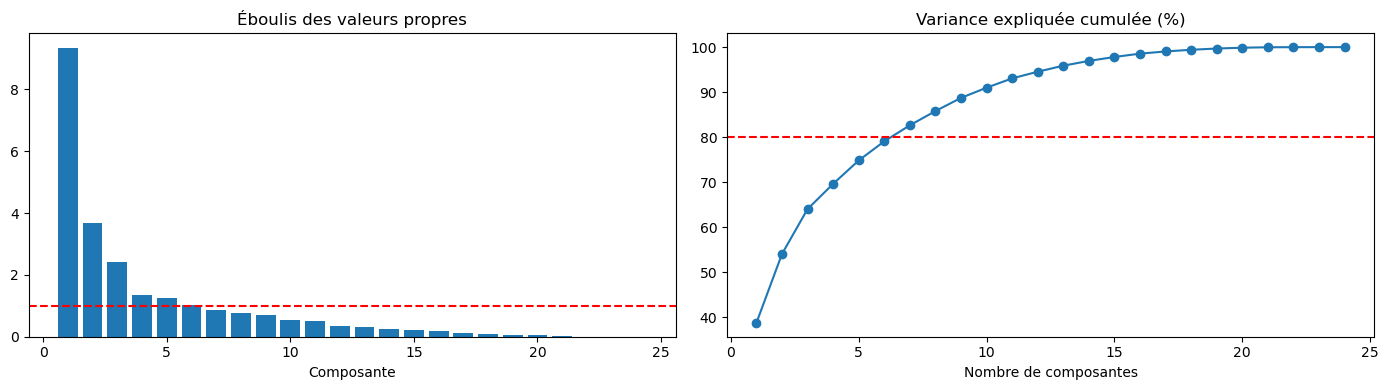

In [4]:
acp_complete = PCA().fit(X)
variance = acp_complete.explained_variance_ratio_
cumul = np.cumsum(variance)
valeurs_propres = acp_complete.explained_variance_

tableau = pd.DataFrame({
    "composante": ["CP" + str(i + 1) for i in range(len(variance))],
    "valeur_propre": valeurs_propres.round(3),
    "variance_%": (variance * 100).round(2),
    "variance_cumulee_%": (cumul * 100).round(2),
})
display(tableau)

N_KAISER = int((valeurs_propres > 1).sum())
N_80 = int(np.argmax(cumul >= 0.80) + 1)
print("Critère de Kaiser (valeur propre > 1) :", N_KAISER, "composantes")
print("Critère des 80 % de variance expliquée :", N_80, "composantes")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(1, len(variance) + 1), valeurs_propres)
axes[0].axhline(1, color="red", linestyle="--")
axes[0].set_title("Éboulis des valeurs propres")
axes[0].set_xlabel("Composante")
axes[1].plot(range(1, len(cumul) + 1), cumul * 100, marker="o")
axes[1].axhline(80, color="red", linestyle="--")
axes[1].set_title("Variance expliquée cumulée (%)")
axes[1].set_xlabel("Nombre de composantes")
plt.tight_layout()
plt.show()

## ACP réduite à 7 composantes

D'après l'éboulis et la variance cumulée :
- le **coude** apparaît après la 3e composante, mais 3 composantes ne gardent que ~64 % de l'information ;
- le **critère de Kaiser** donne 5 composantes sûres et une 6e à la limite (valeur propre ≈ 1), soit ~79 % ;
- le **critère des 80 %** est atteint à la **7e composante** (~82,5 %).

On garde donc **7 composantes** : c'est le plus petit nombre qui conserve plus de 80 % de la variance, et il laisse assez de dimensions pour les variables peu corrélées aux autres (`part_green`, `part_especes`, `croissance_2025`, `part_pmr`), qui sinon disparaîtraient.

**Effet sur les données :** la matrice `X_acp`, une ligne par zone active et 7 colonnes (CP1 à CP7), qui remplace les 24 features corrélées.

In [5]:
N_COMPOSANTES = 7

acp = PCA(n_components=N_COMPOSANTES)
X_acp = pd.DataFrame(acp.fit_transform(X), columns=["CP" + str(i + 1) for i in range(N_COMPOSANTES)])

print("Composantes gardées :", N_COMPOSANTES)
print("Variance conservée :", round(acp.explained_variance_ratio_.sum() * 100, 2), "%")
print("Forme de X_acp :", X_acp.shape)
display(pd.DataFrame({"valeur_propre": acp.explained_variance_.round(3),
                      "variance_%": (acp.explained_variance_ratio_ * 100).round(2)},
                     index=X_acp.columns))

Composantes gardées : 7
Variance conservée : 82.65 %
Forme de X_acp : (257, 7)


,valeur_propre,variance_%
CP1,9.343,38.78
CP2,3.687,15.30
CP3,2.403,9.97
CP4,1.348,5.60
CP5,1.251,5.19
CP6,1.023,4.25
CP7,0.858,3.56


##  interprétation des composantes

Pour donner un sens à chaque composante, on calcule trois indicateurs classiques de l'ACP :

- la **corrélation** entre chaque variable et chaque composante (entre −1 et 1) : son signe dit de quel côté de l'axe la variable tire, sa valeur dit à quel point elle est liée à l'axe ;
- le **cos²** (corrélation au carré) : la part de la variable expliquée par la composante. La somme des cos² sur les 7 composantes donne la **qualité de représentation** de chaque variable : proche de 1, la variable est bien conservée par l'ACP ; faible, elle est en partie perdue ;
- la **contribution** (en %) de chaque variable à la construction de chaque composante : les variables qui contribuent le plus donnent son nom à l'axe.

Pour chaque composante, on affiche les 5 variables qui contribuent le plus, avec leur signe.

**Effet sur les données :** aucun, c'est l'interprétation des axes.

In [6]:
correlations = pd.DataFrame(acp.components_.T * np.sqrt(acp.explained_variance_),
                            index=FEATURES, columns=X_acp.columns)

cos2 = correlations ** 2
qualite = cos2.sum(axis=1).sort_values()
contributions = (acp.components_.T ** 2) * 100
contributions = pd.DataFrame(contributions, index=FEATURES, columns=X_acp.columns)

print("Corrélations variables / composantes :")
display(correlations.round(2))

print("Qualité de représentation de chaque variable sur les", N_COMPOSANTES, "composantes (somme des cos²) :")
display(qualite.round(3).to_frame("cos2_total"))

for cp in X_acp.columns:
    top = contributions[cp].sort_values(ascending=False).head(5)
    signe = correlations.loc[top.index, cp].apply(lambda v: "+" if v > 0 else "-")
    print(cp, ":", ", ".join(signe[v] + v + " (" + str(round(top[v], 1)) + " %)" for v in top.index))

Corrélations variables / composantes :


,CP1,CP2,CP3,CP4,CP5,CP6,CP7
courses_par_jour,0.74,-0.24,-0.11,-0.04,-0.00,0.21,0.14
part_yellow,0.91,-0.19,0.21,-0.05,-0.04,0.00,0.17
part_green,0.05,-0.00,-0.01,0.72,0.46,-0.06,0.25
part_fhv,-0.67,-0.40,0.21,-0.31,0.28,0.11,-0.10
part_vtc,-0.58,0.56,-0.42,0.19,-0.24,-0.08,-0.16
part_weekend,0.43,0.78,-0.06,-0.10,0.17,-0.13,0.04
part_nuit,0.19,0.74,-0.22,-0.30,0.29,-0.04,0.04
part_matin,-0.74,-0.19,-0.29,0.03,0.02,0.25,0.00
part_journee,-0.46,-0.77,0.18,-0.01,-0.01,-0.01,-0.03
part_fin_aprem,0.89,-0.11,0.18,0.21,-0.15,-0.06,0.13


Qualité de représentation de chaque variable sur les 7 composantes (somme des cos²) :


,cos2_total
part_pmr,0.556
croissance_2025,0.573
courses_par_jour,0.692
part_matin,0.728
part_chauffeur,0.787
part_green,0.803
prix_par_mile,0.811
part_nuit,0.811
part_partage,0.831
attente_moy_min,0.838


CP1 : +part_yellow (8.9 %), +part_fin_aprem (8.4 %), +part_cbd (8.3 %), +taux_pourboire (7.8 %), -part_chauffeur (7.3 %)
CP2 : +part_weekend (16.4 %), -part_journee (16.3 %), +part_nuit (14.7 %), +part_vtc (8.5 %), +croissance_2025 (8.4 %)
CP3 : +prix_moy (23.4 %), +part_aeroport (16.9 %), +duree_moy_min (10.9 %), +distance_moy (9.2 %), -part_vtc (7.4 %)
CP4 : +part_green (38.6 %), +part_pmr (14.3 %), -part_fhv (6.9 %), -part_nuit (6.8 %), -attente_moy_min (4.7 %)
CP5 : +part_especes (39.5 %), +part_green (17.3 %), -part_pmr (7.2 %), +part_partage (6.9 %), +part_nuit (6.9 %)
CP6 : +part_aeroport (22.7 %), +part_partage (16.1 %), -part_especes (14.8 %), +croissance_2025 (11.0 %), +prix_par_mile (9.6 %)
CP7 : +attente_moy_min (31.6 %), +part_partage (13.3 %), -part_aeroport (9.2 %), +part_green (7.1 %), +croissance_2025 (7.0 %)


## cercles des corrélations

Le **cercle des corrélations** représente chaque variable par une flèche dans le plan de deux composantes :
- une flèche **longue**, proche du cercle, indique une variable bien représentée dans ce plan ;
- deux flèches dans la **même direction** indiquent des variables corrélées positivement ;
- deux flèches **opposées** indiquent des variables corrélées négativement ;
- deux flèches **perpendiculaires** indiquent des variables indépendantes.

On trace le premier plan (CP1 / CP2) et le deuxième (CP3 / CP4). Pour garder les graphiques lisibles, on n'affiche que les variables assez bien représentées dans le plan (corrélation totale ≥ 0,5).

**Effet sur les données :** aucun, ce sont des graphiques d'interprétation.

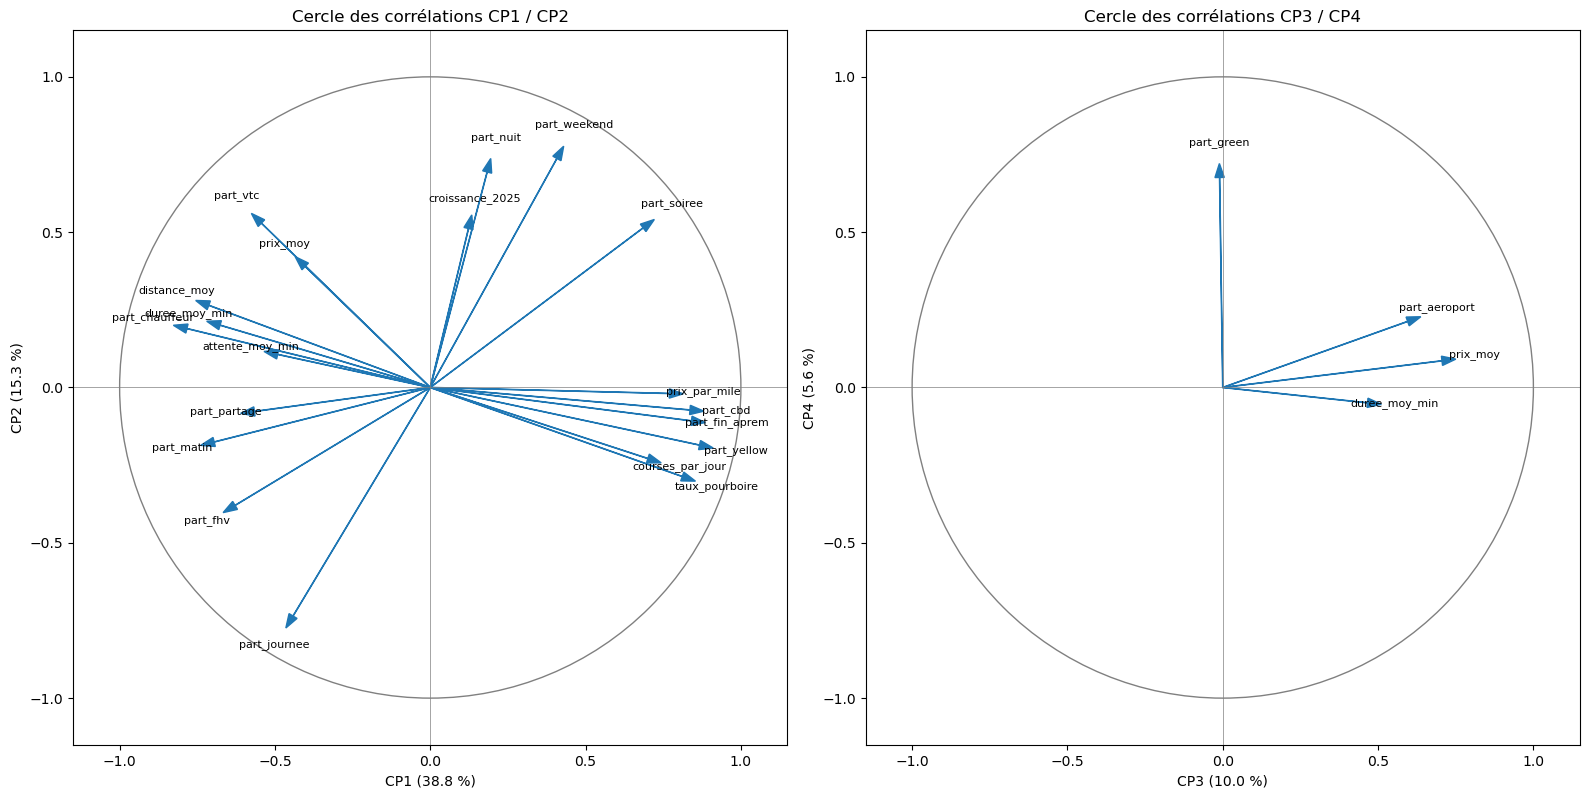

In [7]:
def cercle(cp_x, cp_y, ax):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    for var in FEATURES:
        x, y = correlations.loc[var, cp_x], correlations.loc[var, cp_y]
        if x ** 2 + y ** 2 >= 0.25:
            ax.arrow(0, 0, x, y, head_width=0.03, color="tab:blue", length_includes_head=True)
            ax.text(x * 1.08, y * 1.08, var, fontsize=8, ha="center")
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect("equal")
    i, j = int(cp_x[2:]) - 1, int(cp_y[2:]) - 1
    ax.set_xlabel(cp_x + " (" + str(round(acp.explained_variance_ratio_[i] * 100, 1)) + " %)")
    ax.set_ylabel(cp_y + " (" + str(round(acp.explained_variance_ratio_[j] * 100, 1)) + " %)")
    ax.set_title("Cercle des corrélations " + cp_x + " / " + cp_y)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
cercle("CP1", "CP2", axes[0])
cercle("CP3", "CP4", axes[1])
plt.tight_layout()
plt.show()

## projection des zones sur le premier plan factoriel

Chaque zone active est placée selon ses coordonnées sur CP1 et CP2, avec une couleur par arrondissement (Manhattan, Brooklyn, Queens, Bronx, Staten Island). On affiche le nom des zones les plus extrêmes sur chaque axe pour aider à interpréter : les zones à droite et à gauche de CP1 illustrent ce que mesure le premier axe, celles en haut et en bas illustrent CP2.

Si des **nuages de points** séparés apparaissent déjà sur ce graphique, c'est un premier signe que des segments naturels existent, ce que K-Means devra confirmer.

**Effet sur les données :** aucun, c'est la visualisation des zones dans l'espace de l'ACP.

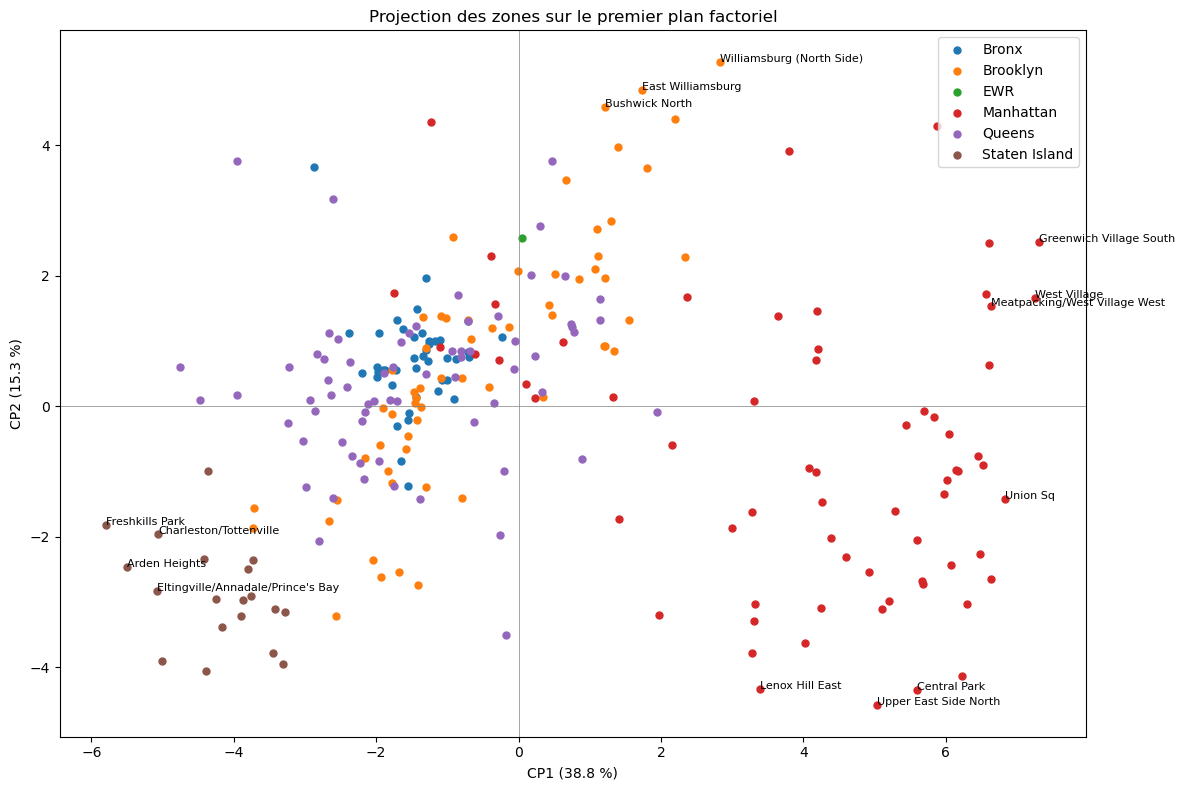

In [8]:
projection = pd.concat([actives[IDENTIFIANTS], X_acp], axis=1)

fig, ax = plt.subplots(figsize=(12, 8))
for arr in sorted(projection["arrondissement"].dropna().unique()):
    sous = projection[projection["arrondissement"] == arr]
    ax.scatter(sous["CP1"], sous["CP2"], s=25, label=arr)

extremes = pd.concat([projection.nlargest(4, "CP1"), projection.nsmallest(4, "CP1"),
                      projection.nlargest(3, "CP2"), projection.nsmallest(3, "CP2")]).drop_duplicates("zone_id")
for _, z in extremes.iterrows():
    ax.annotate(z["nom_zone"], (z["CP1"], z["CP2"]), fontsize=8)

ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("CP1 (" + str(round(acp.explained_variance_ratio_[0] * 100, 1)) + " %)")
ax.set_ylabel("CP2 (" + str(round(acp.explained_variance_ratio_[1] * 100, 1)) + " %)")
ax.set_title("Projection des zones sur le premier plan factoriel")
ax.legend()
plt.tight_layout()
plt.show()

## métriques mathématiques AVANT l'ACP

On lance K-Means pour k = 2 à 10 sur les features standardisées `X`, et pour chaque k on calcule trois indices de qualité de la partition :

- **Score de silhouette** (entre −1 et 1, **plus haut = mieux**) : pour chaque zone, compare la distance moyenne aux zones de son propre groupe avec la distance moyenne aux zones du groupe voisin le plus proche. Une valeur proche de 1 signifie que la zone est bien dans son groupe ; proche de 0, qu'elle est à la frontière ; négative, qu'elle serait mieux dans un autre groupe.
- **Indice de Davies-Bouldin** (≥ 0, **plus bas = mieux**) : moyenne, sur tous les groupes, du rapport entre la dispersion à l'intérieur de deux groupes et la distance entre leurs centres. Il est faible quand les groupes sont compacts et éloignés les uns des autres.
- **Indice de Calinski-Harabasz** (≥ 0, **plus haut = mieux**) : rapport entre la dispersion **entre** les groupes et la dispersion **à l'intérieur** des groupes, corrigé par le nombre de groupes. Il est élevé quand les groupes sont bien séparés et homogènes.

`n_init=20` relance K-Means 20 fois avec des centres de départ différents et garde la meilleure solution ; `random_state=42` rend les résultats reproductibles.

**Effet sur les données :** aucun, on obtient un tableau de scores et le meilleur k selon chaque indice.

In [9]:
K_VALEURS = range(2, 11)

def evaluer_k(donnees, nom):
    lignes = []
    for k in K_VALEURS:
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(donnees)
        lignes.append({
            "k": k,
            "inertie": km.inertia_,
            "silhouette": silhouette_score(donnees, km.labels_),
            "davies_bouldin": davies_bouldin_score(donnees, km.labels_),
            "calinski_harabasz": calinski_harabasz_score(donnees, km.labels_),
        })
    res = pd.DataFrame(lignes)
    print(nom)
    print("  meilleur k selon la silhouette (max) :", int(res.loc[res["silhouette"].idxmax(), "k"]))
    print("  meilleur k selon Davies-Bouldin (min) :", int(res.loc[res["davies_bouldin"].idxmin(), "k"]))
    print("  meilleur k selon Calinski-Harabasz (max) :", int(res.loc[res["calinski_harabasz"].idxmax(), "k"]))
    return res

scores_avant = evaluer_k(X, "AVANT l'ACP (" + str(X.shape[1]) + " features)")
display(scores_avant.round(3))

AVANT l'ACP (24 features)
  meilleur k selon la silhouette (max) : 2
  meilleur k selon Davies-Bouldin (min) : 2
  meilleur k selon Calinski-Harabasz (max) : 2


,k,inertie,silhouette,davies_bouldin,calinski_harabasz
0,2,4304.261,0.374,1.097,110.415
1,3,3696.789,0.253,1.524,84.896
2,4,3266.059,0.265,1.636,74.931
3,5,2961.425,0.263,1.496,68.215
4,6,2756.226,0.260,1.476,62.140
5,7,2577.516,0.247,1.424,58.042
6,8,2421.667,0.258,1.222,55.029
7,9,2287.904,0.200,1.403,52.573
8,10,2174.972,0.183,1.391,50.385


## métriques mathématiques APRÈS l'ACP

On refait exactement le même test, avec les mêmes k et les mêmes réglages, mais sur les **7 composantes** `X_acp`.

- Si les deux espaces donnent le **même k**, la segmentation est **robuste** : elle ne dépend pas de la représentation choisie.
- Si la silhouette est **égale ou meilleure** après l'ACP, cela prouve que l'ACP a retiré de la redondance et du bruit sans détruire la structure des groupes.

**Effet sur les données :** aucun, on obtient le tableau de scores après l'ACP.

In [11]:
scores_apres = evaluer_k(X_acp, "APRÈS l'ACP (" + str(N_COMPOSANTES) + " composantes)")
display(scores_apres.round(3))

APRÈS l'ACP (7 composantes)
  meilleur k selon la silhouette (max) : 2
  meilleur k selon Davies-Bouldin (min) : 2
  meilleur k selon Calinski-Harabasz (max) : 2


,k,inertie,silhouette,davies_bouldin,calinski_harabasz
0,2,3236.997,0.434,0.939,146.599
1,3,2639.300,0.303,1.418,118.307
2,4,2214.588,0.325,1.328,109.801
3,5,1933.918,0.333,1.224,103.072
4,6,1751.555,0.309,1.234,95.908
5,7,1591.643,0.320,1.116,91.789
6,8,1451.420,0.310,1.039,89.369
7,9,1329.430,0.240,1.154,87.875
8,10,1261.653,0.232,1.176,83.450


##  comparaison graphique des trois métriques

On trace chaque métrique en fonction de k, avec une courbe avant l'ACP et une courbe après. Le bon k est celui où :
- la **silhouette** atteint un pic,
- **Davies-Bouldin** atteint un creux,
- **Calinski-Harabasz** reste élevé.

Les trois indices ne donnent pas toujours le même k : Calinski-Harabasz favorise souvent les petits k, et la silhouette peut rester proche entre deux valeurs. On cherche donc le k qui fait le **meilleur compromis**.

**Effet sur les données :** aucun, ce sont des graphiques de comparaison.

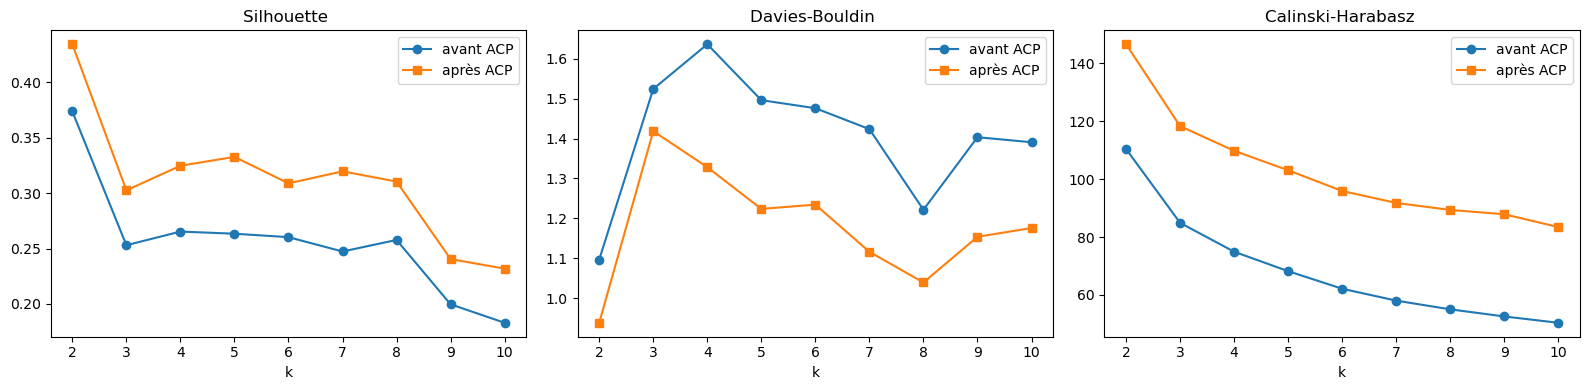

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, titre in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                          ["Silhouette ", "Davies-Bouldin ", "Calinski-Harabasz "]):
    ax.plot(scores_avant["k"], scores_avant[col], marker="o", label="avant ACP")
    ax.plot(scores_apres["k"], scores_apres[col], marker="s", label="après ACP")
    ax.set_title(titre)
    ax.set_xlabel("k")
    ax.legend()
plt.tight_layout()
plt.show()

## méthode du coude avec KneeLocator

L'**inertie** (somme des distances au carré entre chaque zone et le centre de son groupe) baisse toujours quand k augmente. Au début, ajouter un groupe la fait chuter fortement ; à partir d'un certain k, le gain devient faible. Ce point de rupture est le **coude** : au-delà, on découpe des groupes qui existent déjà au lieu d'en découvrir de nouveaux.

On calcule l'inertie pour k = 1 à 10, avant et après l'ACP, et on détecte le coude avec `KneeLocator` de la bibliothèque `kneed` :
- `curve="convex"` : la courbe d'inertie est convexe (elle s'aplatit progressivement) ;
- `direction="decreasing"` : l'inertie diminue quand k augmente.

KneeLocator normalise la courbe et cherche le point où elle s'écarte le plus de la droite qui relie son premier et son dernier point, c'est-à-dire là où la baisse de l'inertie ralentit le plus nettement. On affiche les deux courbes avec le coude trouvé.

**Effet sur les données :** aucun, on obtient le k du coude avant et après l'ACP.

In [19]:
%pip install kneed

  Using cached kneed-0.9.0-py3-none-any.whl.metadata (6.4 kB)
Note: you may need to restart the kernel to use updated packages.


Coude AVANT l'ACP : k = 3
Coude APRÈS l'ACP : k = 3


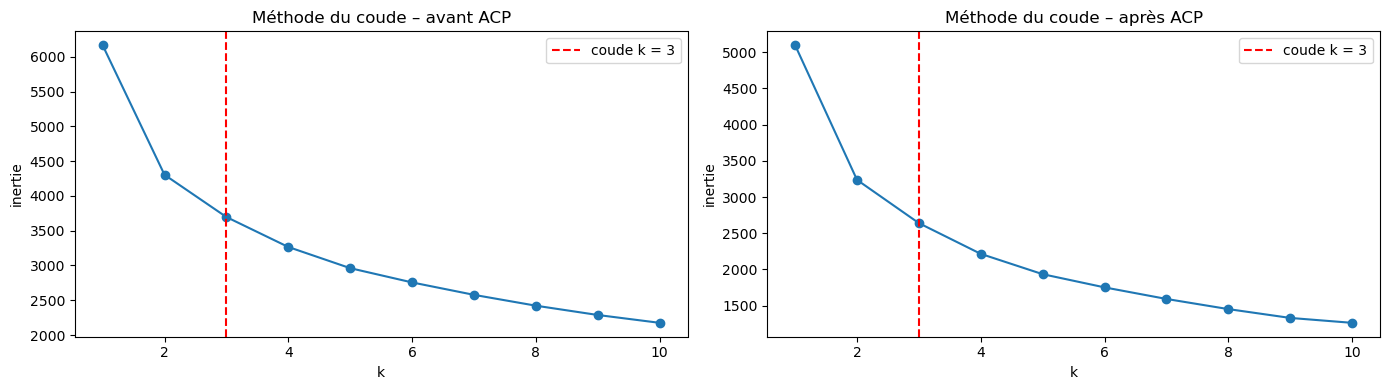

In [20]:
from kneed import KneeLocator

K_COUDE = list(range(1, 11))
inerties_avant = [KMeans(n_clusters=k, n_init=20, random_state=42).fit(X).inertia_ for k in K_COUDE]
inerties_apres = [KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_acp).inertia_ for k in K_COUDE]

kl_avant = KneeLocator(K_COUDE, inerties_avant, curve="convex", direction="decreasing")
kl_apres = KneeLocator(K_COUDE, inerties_apres, curve="convex", direction="decreasing")
coude_avant = kl_avant.knee
coude_apres = kl_apres.knee

print("Coude AVANT l'ACP : k =", coude_avant)
print("Coude APRÈS l'ACP : k =", coude_apres)
if coude_avant is None or coude_apres is None:
    print("KneeLocator n'a pas trouvé de coude net sur au moins une courbe : la courbe est trop régulière.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, inerties, k_c, titre in [(axes[0], inerties_avant, coude_avant, "Méthode du coude – avant ACP"),
                                 (axes[1], inerties_apres, coude_apres, "Méthode du coude – après ACP")]:
    ax.plot(K_COUDE, inerties, marker="o")
    if k_c is not None:
        ax.axvline(k_c, color="red", linestyle="--", label="coude k = " + str(k_c))
        ax.legend()
    ax.set_title(titre)
    ax.set_xlabel("k")
    ax.set_ylabel("inertie")
plt.tight_layout()
plt.show()

## synthèse des critères et sauvegarde

On rassemble dans un seul tableau le meilleur k selon chacun des 4 critères (silhouette, Davies-Bouldin, Calinski-Harabasz, coude), avant et après l'ACP. Le k final se choisit en croisant :
- le **consensus** entre les critères ;
- la **stabilité** entre l'analyse avant et après l'ACP ;
- l'**interprétabilité** : des segments qu'on sait décrire et nommer, sans groupe minuscule de 2 ou 3 zones.

On sauvegarde dans `ml_data` tout ce dont les étapes suivantes (K-Means final, CAH, DBSCAN) auront besoin : la liste des zones actives, `X` standardisé, `X_acp` et les deux tableaux de scores.

**Effet sur les données :** aucun changement, les matrices et les scores sont gardés sur le disque.

In [17]:
def meilleurs(res, k_coude):
    return {
        "silhouette": int(res.loc[res["silhouette"].idxmax(), "k"]),
        "davies_bouldin": int(res.loc[res["davies_bouldin"].idxmin(), "k"]),
        "calinski_harabasz": int(res.loc[res["calinski_harabasz"].idxmax(), "k"]),
        "coude": k_coude,
    }

synthese = pd.DataFrame({"avant_ACP": meilleurs(scores_avant, coude_avant),
                         "apres_ACP": meilleurs(scores_apres, coude_apres)})
display(synthese)

actives[IDENTIFIANTS].to_csv(os.path.join(ML_DIR, "zones_actives.csv"), index=False)
X.to_csv(os.path.join(ML_DIR, "X_standardise.csv"), index=False)
X_acp.to_csv(os.path.join(ML_DIR, "X_acp.csv"), index=False)
scores_avant.to_csv(os.path.join(ML_DIR, "scores_k_avant_acp.csv"), index=False)
scores_apres.to_csv(os.path.join(ML_DIR, "scores_k_apres_acp.csv"), index=False)
print("Fichiers sauvegardés dans :", ML_DIR)

,avant_ACP,apres_ACP
silhouette,2,2
davies_bouldin,2,2
calinski_harabasz,2,2
coude,3,3


Fichiers sauvegardés dans : c:\Users\DELL\Desktop\esprit\ML\notebook_v0\Nootebook_vf\ml_data


Sur votre projection, la CP1, qui porte 38,8 % de l’information, oppose très nettement Manhattan, à droite, au reste de la ville, à gauche. C’est la séparation la plus forte des données, et K-Means avec k = 2 coupe exactement là. La silhouette, Davies-Bouldin et Calinski-Harabasz favorisent naturellement la coupure la plus nette, et Calinski-Harabasz est en plus connu pour privilégier les petits k.

Le problème, c’est qu’un résultat « Manhattan contre le reste » n’apprend rien : n’importe quel New-Yorkais le sait déjà. Pour un objectif de segmentation suivie de recommandations, k = 2 est trop grossier.

## comparaison visuelle de k = 2, 3 et 4

Les trois métriques désignent k = 2 et la méthode du coude k = 3. Les métriques favorisent la coupure la plus nette des données, ici Manhattan contre le reste de la ville (axe CP1), mais cette segmentation est trop grossière pour formuler des recommandations.

On compare donc concrètement k = 2, 3 et 4 sur l'espace de l'ACP :
- la **silhouette** de chaque solution, pour mesurer la perte de qualité quand on ajoute un groupe ;
- la **taille des groupes**, pour éviter les groupes minuscules ;
- le **croisement avec les arrondissements**, pour vérifier que chaque groupe a un sens géographique ;
- la **projection** sur le premier plan factoriel, colorée par groupe.

Le k retenu est celui qui garde une silhouette proche du maximum tout en donnant des groupes interprétables et utiles.

**Effet sur les données :** trois colonnes `cluster_k2`, `cluster_k3` et `cluster_k4` sont ajoutées à la table `projection`, pour la comparaison.

k = 2 | silhouette = 0.434 | tailles des groupes = [202, 55]


arrondissement,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island
cluster_k2,,,,,,
0,42,61,1,12,67,19
1,0,0,0,54,1,0


k = 3 | silhouette = 0.303 | tailles des groupes = [51, 135, 71]


arrondissement,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island
cluster_k3,,,,,,
0,0,0,0,51,0,0
1,39,32,0,1,44,19
2,3,29,1,14,24,0


k = 4 | silhouette = 0.325 | tailles des groupes = [59, 118, 29, 51]


arrondissement,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island
cluster_k4,,,,,,
0,1,24,1,12,21,0
1,41,34,0,3,40,0
2,0,3,0,0,7,19
3,0,0,0,51,0,0


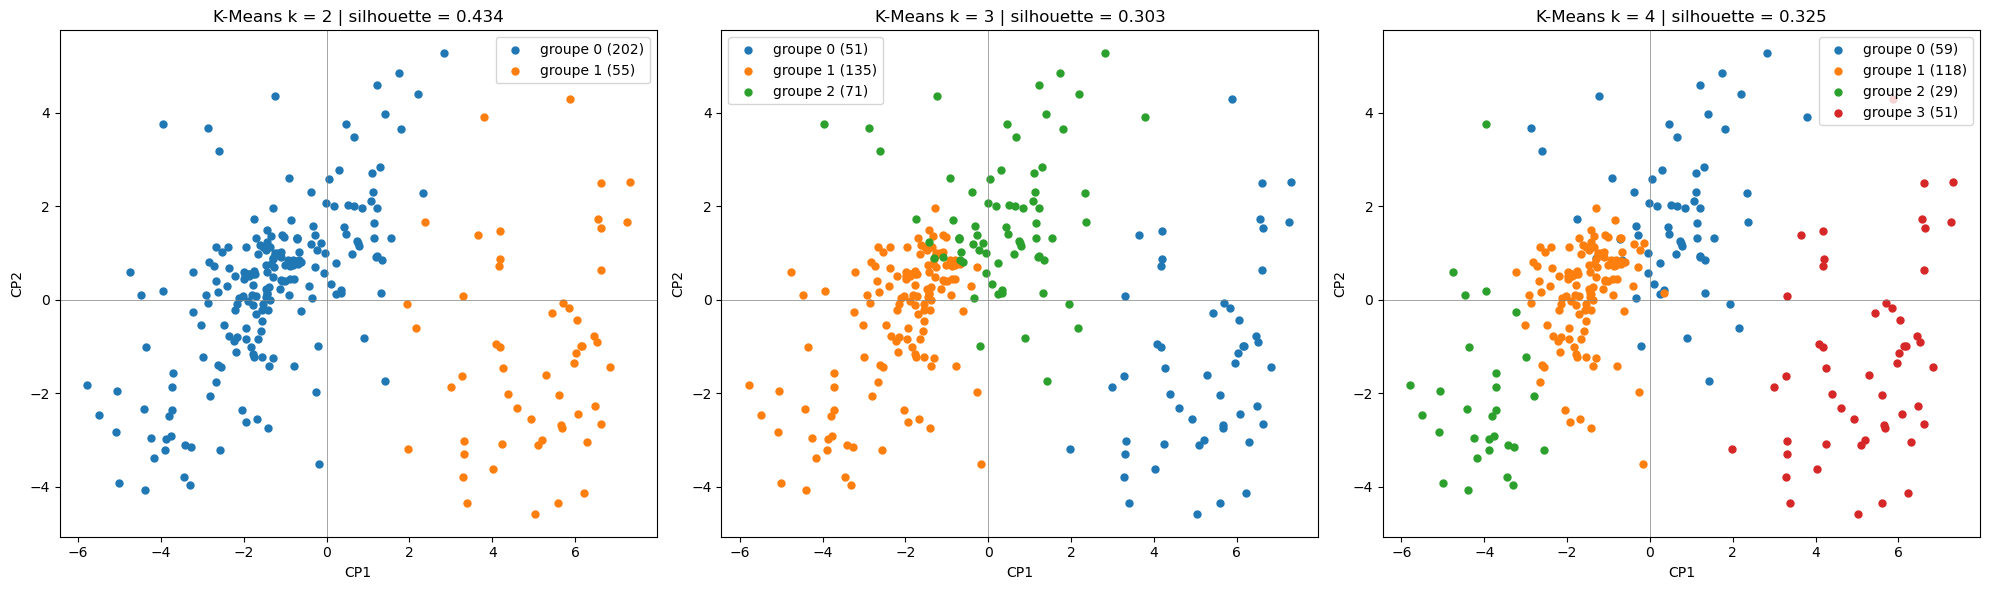

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, k in zip(axes, [2, 3, 4]):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_acp)
    labels = km.labels_
    projection["cluster_k" + str(k)] = labels

    sil = silhouette_score(X_acp, labels)
    tailles = pd.Series(labels).value_counts().sort_index().tolist()
    print("k =", k, "| silhouette =", round(sil, 3), "| tailles des groupes =", tailles)
    display(pd.crosstab(projection["cluster_k" + str(k)], projection["arrondissement"]))

    for c in range(k):
        sous = projection[projection["cluster_k" + str(k)] == c]
        ax.scatter(sous["CP1"], sous["CP2"], s=25, label="groupe " + str(c) + " (" + str(len(sous)) + ")")
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title("K-Means k = " + str(k) + " | silhouette = " + str(round(sil, 3)))
    ax.set_xlabel("CP1")
    ax.set_ylabel("CP2")
    ax.legend()
plt.tight_layout()
plt.show()

k = 2 : la meilleure silhouette, mais une coupure triviale

Avec une silhouette de 0,434, c’est la partition la plus nette. Mais le tableau montre ce qu’elle fait : le groupe 1 contient 54 zones de Manhattan et 1 zone du Queens, et le groupe 0 contient tout le reste. Elle se contente de séparer le centre de Manhattan du reste de New York. On remarque même que 12 zones de Manhattan, sans doute le nord (Harlem, Washington Heights, Inwood), sont rangées avec les quartiers périphériques. C’est cohérent, mais trop pauvre pour formuler des recommandations.

k = 3 : la plus mauvaise des trois

La silhouette chute à 0,303, et la partition n’isole pas ce qu’on attendait. Le groupe 0 contient les 51 zones du cœur de Manhattan, ce qui est clair. Mais le groupe 1, avec 135 zones, mélange le Bronx, Brooklyn, le Queens et Staten Island. Staten Island n’est donc pas séparé, contrairement à ce que le graphique laissait penser. Le groupe 2, avec 71 zones, est un mélange de Brooklyn, du Queens et de 14 zones de Manhattan, sans profil net. Votre intuition sur les 3 nuages était juste visuellement, mais K-Means ne coupe pas là avec k = 3.

k = 4 : la meilleure solution

D’abord, sa silhouette (0,325) est plus élevée qu’avec k = 3. Ajouter un quatrième groupe améliore donc la qualité au lieu de la dégrader : c’est le signe qu’il correspond à une vraie structure des données. Ensuite, chacun des 4 groupes a un sens géographique clair :     

Groupe 3 (51 zones) : uniquement Manhattan. C’est le cœur de Manhattan (Midtown, Financial District, Upper East et West Side, Village), dominé par les taxis jaunes et soumis au péage CBD. On y retrouve les 51 mêmes zones que le groupe 0 de k = 3, ce qui prouve que ce segment est très stable.    
Groupe 2 (29 zones) : 19 zones de Staten Island, 7 du Queens et 3 de Brooklyn. Ce sont les zones périphériques éloignées, résidentielles et peu denses, avec des courses longues. C’est exactement le nuage en bas à gauche de votre premier graphique : k = 4 l’isole enfin.     
Groupe 1 (118 zones) : 41 zones du Bronx, 40 du Queens, 34 de Brooklyn et 3 de Manhattan. Ce sont les quartiers périphériques denses, dominés par les VTC.     
Groupe 0 (59 zones) : 24 zones de Brooklyn, 21 du Queens, 12 de Manhattan et l’aéroport de Newark. Ce sont les quartiers intermédiaires, en haut du graphique : Williamsburg, Bushwick, Long Island City et Astoria, ainsi que le nord de Manhattan. Ces quartiers en transition ou tournés vers les sorties, à mi-chemin entre le centre et la périphérie, ont un mix de taxis et de VTC plus équilibré.      

##  k = 4 ou k = 5 ?

Le tableau des scores après l'ACP montre que **k = 5** améliore la silhouette (0,333 contre 0,325) et Davies-Bouldin (1,224 contre 1,328) par rapport à k = 4, alors que k = 6 dégrade les trois indices. k = 5 est donc un **optimum local**. Calinski-Harabasz baisse légèrement, mais cet indice favorise mécaniquement les petits k.

L'écart étant faible, on vérifie que le cinquième groupe a un sens :
- la **taille** des groupes, pour écarter un groupe minuscule et artificiel ;
- la **répartition par arrondissement** de chaque groupe ;
- le **tableau croisé k = 4 / k = 5**, qui montre quel groupe de k = 4 se divise pour former le cinquième ;
- la **projection** des deux solutions sur le premier plan factoriel.

**Effet sur les données :** les colonnes `cluster_k4` et `cluster_k5` sont ajoutées à la table `projection`.

k = 4 | silhouette = 0.325 | tailles des groupes = [59, 118, 29, 51]


arrondissement,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island
cluster_k4,,,,,,
0,1,24,1,12,21,0
1,41,34,0,3,40,0
2,0,3,0,0,7,19
3,0,0,0,51,0,0


k = 5 | silhouette = 0.333 | tailles des groupes = [50, 120, 50, 13, 24]


arrondissement,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island
cluster_k5,,,,,,
0,0,23,0,11,16,0
1,41,34,0,3,42,0
2,0,0,0,50,0,0
3,1,1,1,2,8,0
4,0,3,0,0,2,19


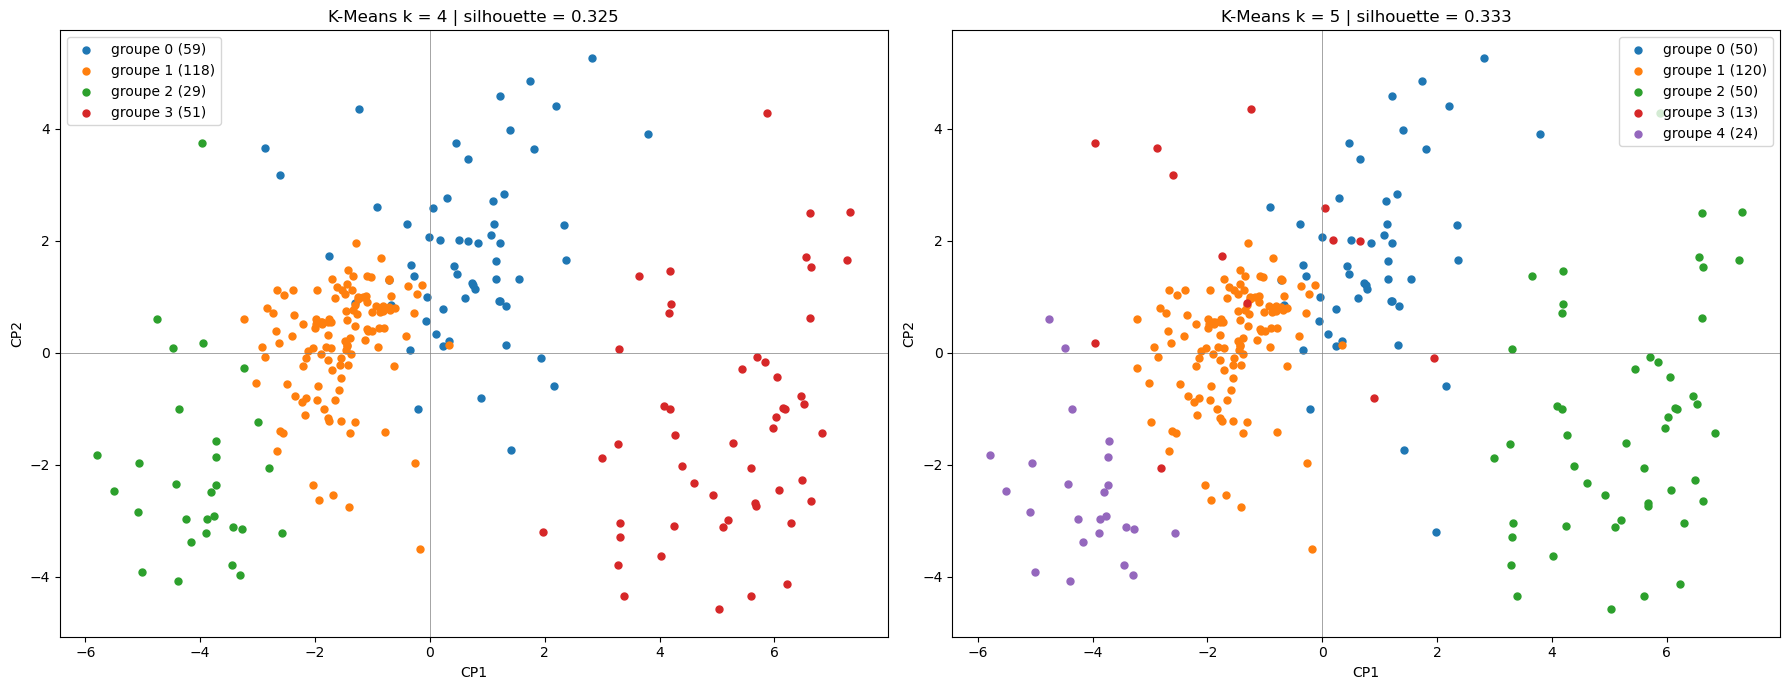

Comment les groupes de k = 4 se répartissent dans k = 5 :


groupe k=5,0,1,2,3,4
groupe k=4,,,,,
0,49,0,0,10,0
1,0,118,0,0,0
2,0,2,0,3,24
3,1,0,50,0,0


k=5, groupe 0 : Alphabet City, Astoria, Astoria Park, Bedford, Boerum Hill, Brooklyn Heights, Brooklyn Navy Yard, Bushwick North
k=5, groupe 1 : Allerton/Pelham Gardens, Auburndale, Baisley Park, Bath Beach, Bay Ridge, Bay Terrace/Fort Totten, Bayside, Bedford Park
k=5, groupe 2 : Battery Park, Battery Park City, Bloomingdale, Central Park, Chinatown, Clinton East, Clinton West, East Chelsea
k=5, groupe 3 : Newark Airport, Breezy Point/Fort Tilden/Riis Beach, Broad Channel, City Island, East Elmhurst, Flushing Meadows-Corona Park, JFK Airport, LaGuardia Airport
k=5, groupe 4 : Arden Heights, Arrochar/Fort Wadsworth, Bloomfield/Emerson Hill, Brighton Beach, Charleston/Tottenville, Coney Island, Eltingville/Annadale/Prince's Bay, Far Rockaway


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, k in zip(axes, [4, 5]):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_acp)
    projection["cluster_k" + str(k)] = km.labels_

    sil = silhouette_score(X_acp, km.labels_)
    tailles = pd.Series(km.labels_).value_counts().sort_index().tolist()
    print("k =", k, "| silhouette =", round(sil, 3), "| tailles des groupes =", tailles)
    display(pd.crosstab(projection["cluster_k" + str(k)], projection["arrondissement"]))

    for c in range(k):
        sous = projection[projection["cluster_k" + str(k)] == c]
        ax.scatter(sous["CP1"], sous["CP2"], s=25, label="groupe " + str(c) + " (" + str(len(sous)) + ")")
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title("K-Means k = " + str(k) + " | silhouette = " + str(round(sil, 3)))
    ax.set_xlabel("CP1")
    ax.set_ylabel("CP2")
    ax.legend()
plt.tight_layout()
plt.show()

print("Comment les groupes de k = 4 se répartissent dans k = 5 :")
display(pd.crosstab(projection["cluster_k4"], projection["cluster_k5"],
                    rownames=["groupe k=4"], colnames=["groupe k=5"]))

for c in sorted(projection["cluster_k5"].unique()):
    noms = projection.loc[projection["cluster_k5"] == c, "nom_zone"].head(8).tolist()
    print("k=5, groupe", c, ":", ", ".join(noms))

##  K-Means final avec k = 5

On applique K-Means avec **k = 5** sur les 7 composantes de l'ACP, avec les mêmes réglages qu'à la cellule 11 (`n_init=20`, `random_state=42`) pour retrouver exactement les mêmes groupes. Chaque zone active reçoit son numéro de segment dans la colonne `segment_km`.

On affiche les trois métriques de qualité de la partition finale et la répartition des segments par arrondissement.

**Effet sur les données :** la table `actives` reçoit la colonne `segment_km` (0 à 4).

In [23]:
K_FINAL = 5

km_final = KMeans(n_clusters=K_FINAL, n_init=20, random_state=42).fit(X_acp)
actives["segment_km"] = km_final.labels_

print("Silhouette finale :", round(silhouette_score(X_acp, km_final.labels_), 3))
print("Davies-Bouldin final :", round(davies_bouldin_score(X_acp, km_final.labels_), 3))
print("Calinski-Harabasz final :", round(calinski_harabasz_score(X_acp, km_final.labels_), 1))
display(pd.crosstab(actives["segment_km"], actives["arrondissement"], margins=True, margins_name="total"))

Silhouette finale : 0.333
Davies-Bouldin final : 1.224
Calinski-Harabasz final : 103.1


arrondissement,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island,total
segment_km,,,,,,,
0,0,23,0,11,16,0,50
1,41,34,0,3,42,0,120
2,0,0,0,50,0,0,50
3,1,1,1,2,8,0,13
4,0,3,0,0,2,19,24
total,42,61,1,66,68,19,257


## taille des segments

On représente le nombre de zones de chaque segment par un histogramme, puis on liste les premières zones de chaque segment pour se faire une idée concrète de leur géographie.



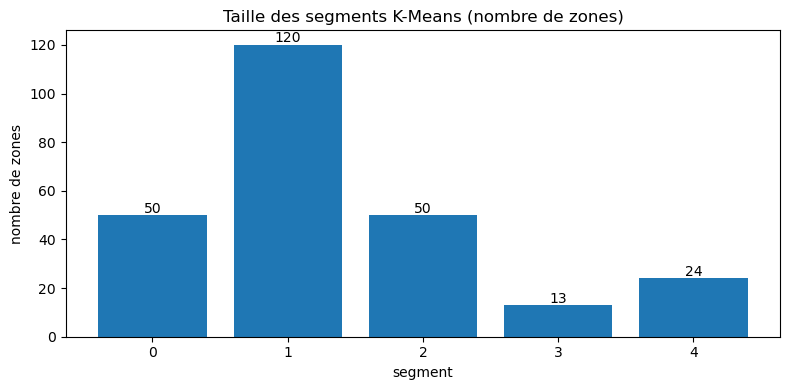

Segment 0 (50 zones) : Alphabet City, Astoria, Astoria Park, Bedford, Boerum Hill, Brooklyn Heights, Brooklyn Navy Yard, Bushwick North, Bushwick South, Carroll Gardens, Central Harlem, Central Harlem North ...
Segment 1 (120 zones) : Allerton/Pelham Gardens, Auburndale, Baisley Park, Bath Beach, Bay Ridge, Bay Terrace/Fort Totten, Bayside, Bedford Park, Bellerose, Belmont, Bensonhurst East, Bensonhurst West ...
Segment 2 (50 zones) : Battery Park, Battery Park City, Bloomingdale, Central Park, Chinatown, Clinton East, Clinton West, East Chelsea, East Village, Financial District North, Financial District South, Flatiron ...
Segment 3 (13 zones) : Newark Airport, Breezy Point/Fort Tilden/Riis Beach, Broad Channel, City Island, East Elmhurst, Flushing Meadows-Corona Park, JFK Airport, LaGuardia Airport, Marine Park/Floyd Bennett Field, Randalls Island, Rockaway Park, Roosevelt Island ...
Segment 4 (24 zones) : Arden Heights, Arrochar/Fort Wadsworth, Bloomfield/Emerson Hill, Brighton Beac

In [24]:
tailles = actives["segment_km"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
barres = plt.bar(tailles.index.astype(str), tailles.values, color="tab:blue")
for b, v in zip(barres, tailles.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 1, str(v), ha="center")
plt.title("Taille des segments K-Means (nombre de zones)")
plt.xlabel("segment")
plt.ylabel("nombre de zones")
plt.tight_layout()
plt.show()

for s in tailles.index:
    noms = actives.loc[actives["segment_km"] == s, "nom_zone"].tolist()
    print("Segment", s, "(" + str(len(noms)) + " zones) :", ", ".join(noms[:12]), "..." if len(noms) > 12 else "")

## profil moyen et variables dominantes de chaque segment

Pour décrire les segments, on revient aux **24 features d'origine**, plus faciles à interpréter que les composantes de l'ACP. On calcule deux tableaux :

- le **profil moyen** en valeurs réelles (par exemple « 0,62 de part de taxis jaunes », « 14 minutes de durée moyenne »), comparé à la moyenne de toutes les zones ;
- les **écarts à la moyenne** en écarts-types, calculés sur les données standardisées : +1,5 signifie que le segment est très au-dessus de la moyenne pour cette variable, −1,5 très en dessous.

Les variables avec les plus grands écarts sont les **variables dominantes** du segment : ce sont elles qui le distinguent des autres et qui servent à le nommer. Pour chaque segment, on affiche les 4 variables les plus au-dessus et les 3 les plus en dessous de la moyenne.



In [25]:
profil_moyen = actives.groupby("segment_km")[FEATURES].mean()
moyenne_ville = actives[FEATURES].mean()
print("Profil moyen de chaque segment (valeurs réelles) :")
display(profil_moyen.T.round(3).assign(moyenne_ville=moyenne_ville.round(3)))

ecarts = X.groupby(actives["segment_km"]).mean()
print("Écarts à la moyenne en écarts-types (> 0 : au-dessus de la moyenne des zones) :")
display(ecarts.T.round(2))

for s in ecarts.index:
    haut = ecarts.loc[s].sort_values(ascending=False).head(4)
    bas = ecarts.loc[s].sort_values().head(3)
    print("\nSegment", s, "(" + str(tailles[s]) + " zones)")
    print("  nettement AU-DESSUS :", ", ".join(v + " (+" + str(round(haut[v], 2)) + ")" for v in haut.index))
    print("  nettement EN DESSOUS :", ", ".join(v + " (" + str(round(bas[v], 2)) + ")" for v in bas.index))

Profil moyen de chaque segment (valeurs réelles) :


segment_km,0,1,2,3,4,moyenne_ville
courses_par_jour,354.277,147.065,2317.529,786.427,125.394,639.966
part_yellow,0.282,0.131,0.863,0.414,0.027,0.307
part_green,0.054,0.006,0.004,0.008,0.002,0.015
part_fhv,0.094,0.188,0.015,0.180,0.682,0.182
part_vtc,0.570,0.675,0.118,0.397,0.289,0.496
part_weekend,0.367,0.283,0.319,0.334,0.203,0.302
part_nuit,0.135,0.097,0.094,0.088,0.058,0.100
part_matin,0.171,0.230,0.119,0.141,0.266,0.196
part_journee,0.268,0.330,0.302,0.320,0.454,0.323
part_fin_aprem,0.146,0.097,0.251,0.151,0.036,0.133


Écarts à la moyenne en écarts-types (> 0 : au-dessus de la moyenne des zones) :


segment_km,0,1,2,3,4
courses_par_jour,0.15,-0.41,1.35,-1.06,-0.49
part_yellow,-0.08,-0.58,1.83,0.35,-0.92
part_green,1.03,-0.22,-0.29,-0.17,-0.34
part_fhv,-0.44,0.03,-0.83,-0.01,2.48
part_vtc,0.29,0.71,-1.51,-0.39,-0.83
part_weekend,0.93,-0.26,0.25,0.46,-1.41
part_nuit,0.67,-0.05,-0.11,-0.22,-0.79
part_matin,-0.37,0.50,-1.13,-0.80,1.03
part_journee,-0.75,0.09,-0.29,-0.04,1.75
part_fin_aprem,0.17,-0.50,1.62,0.24,-1.35



Segment 0 (50 zones)
  nettement AU-DESSUS : part_green (+1.03), croissance_2025 (+0.99), part_weekend (+0.93), part_nuit (+0.67)
  nettement EN DESSOUS : part_journee (-0.75), part_fhv (-0.44), attente_moy_min (-0.39)

Segment 1 (120 zones)
  nettement AU-DESSUS : part_vtc (+0.71), part_chauffeur (+0.54), part_matin (+0.5), part_partage (+0.26)
  nettement EN DESSOUS : taux_pourboire (-0.67), part_yellow (-0.58), part_cbd (-0.56)

Segment 2 (50 zones)
  nettement AU-DESSUS : part_yellow (+1.83), taux_pourboire (+1.79), part_cbd (+1.77), part_fin_aprem (+1.62)
  nettement EN DESSOUS : part_chauffeur (-1.59), part_vtc (-1.51), distance_moy (-1.39)

Segment 3 (13 zones)
  nettement AU-DESSUS : prix_moy (+2.83), attente_moy_min (+2.24), distance_moy (+2.03), duree_moy_min (+1.73)
  nettement EN DESSOUS : courses_par_jour (-1.06), part_matin (-0.8), part_partage (-0.73)

Segment 4 (24 zones)
  nettement AU-DESSUS : part_fhv (+2.48), part_journee (+1.75), attente_moy_min (+1.35), part_part

##  visualisation des variables dominantes

Deux graphiques :
- une **carte de chaleur** : une ligne par segment, une colonne par variable ; rouge = au-dessus de la moyenne, bleu = en dessous. On voit d'un coup d'œil ce qui caractérise chaque segment et ce qui les oppose ;
- un **histogramme horizontal par segment** avec ses 6 variables les plus marquées (en valeur absolue), en rouge si le segment est au-dessus de la moyenne, en bleu s'il est en dessous.

**Effet sur les données :** aucun, ce sont des graphiques d'interprétation.

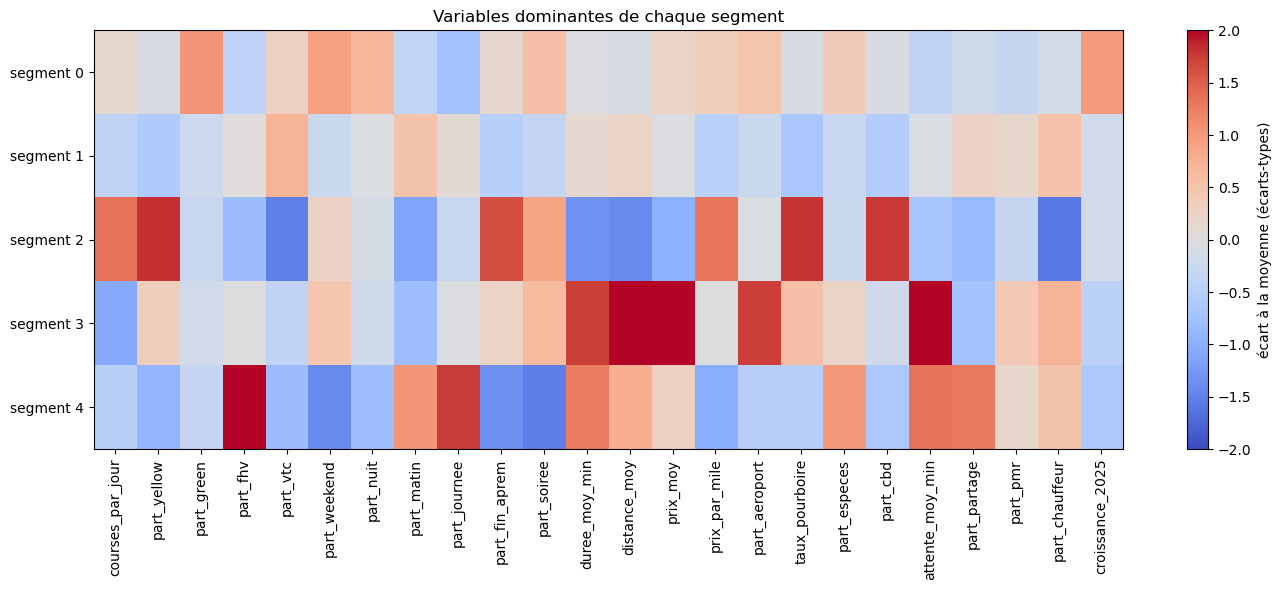

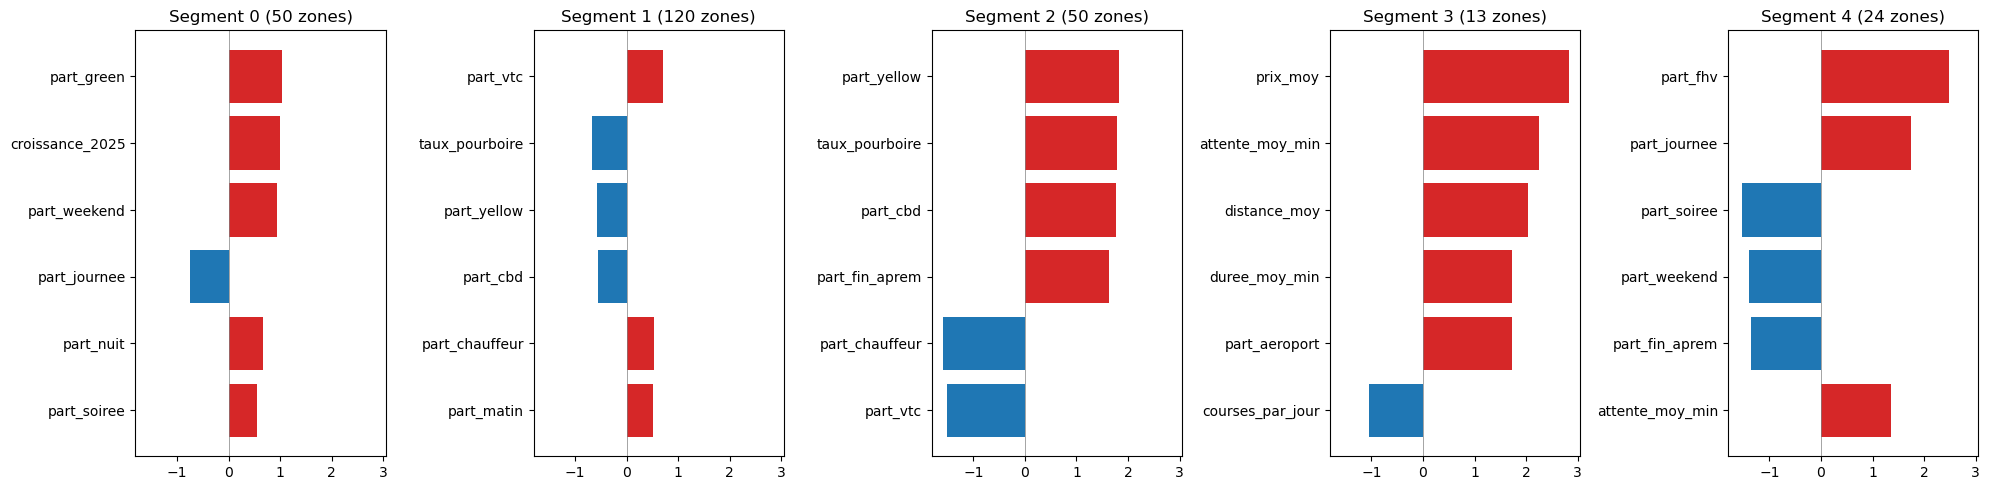

In [26]:
plt.figure(figsize=(14, 6))
plt.imshow(ecarts, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
plt.colorbar(label="écart à la moyenne (écarts-types)")
plt.xticks(range(len(FEATURES)), FEATURES, rotation=90)
plt.yticks(range(K_FINAL), ["segment " + str(s) for s in ecarts.index])
plt.title("Variables dominantes de chaque segment")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, K_FINAL, figsize=(4 * K_FINAL, 5), sharex=True)
for ax, s in zip(axes, ecarts.index):
    top = ecarts.loc[s].reindex(ecarts.loc[s].abs().sort_values(ascending=False).index).head(6)
    couleurs = ["tab:red" if v > 0 else "tab:blue" for v in top.values]
    ax.barh(top.index[::-1], top.values[::-1], color=couleurs[::-1])
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title("Segment " + str(s) + " (" + str(tailles[s]) + " zones)")
plt.tight_layout()
plt.show()

## nommage et vérification des segments

Chaque segment reçoit un nom simple, tiré de ses variables dominantes (cellules 14 et 15) :

- **Manhattan taxi** (segment 2) : taxis jaunes, péage CBD, pourboires élevés, pic en fin d'après-midi, trajets courts ; peu de VTC.
- **Quartiers de sortie** (segment 0) : courses le soir, la nuit et le week-end, taxis verts présents, plus forte croissance 2024 → 2025 ; peu de courses en journée.
- **Résidentiel VTC** (segment 1) : Uber et Lyft dominants, départs le matin, courses partagées ; peu de taxis jaunes et de péage.
- **Banlieue FHV** (segment 4) : VTC classiques réservés auprès d'une base, courses de jour en semaine, attente longue ; peu d'activité le soir et le week-end.
- **Aéroports et longs trajets** (segment 3) : courses longues, chères, souvent vers les aéroports, attente longue ; peu de courses par jour.

**Vérification automatique :** pour chaque nom, on indique la variable qui le justifie, et on contrôle que le segment ainsi nommé est bien celui qui a l'écart le plus fort sur cette variable parmi les 5 segments. Si une ligne affiche « À CORRIGER », c'est que les numéros ne correspondent pas et qu'il faut modifier le dictionnaire.

**Effet sur les données :** la colonne `nom_segment_km` est ajoutée à `actives`.

In [27]:
NOMS_SEGMENTS = {
    2: "Manhattan taxi",
    0: "Quartiers de sortie",
    1: "Résidentiel VTC",
    4: "Banlieue FHV",
    3: "Aéroports et longs trajets",
}

VARIABLE_CLE = {
    "Manhattan taxi": "part_yellow",
    "Quartiers de sortie": "part_weekend",
    "Résidentiel VTC": "part_vtc",
    "Banlieue FHV": "part_fhv",
    "Aéroports et longs trajets": "prix_moy",
}

for segment, nom in NOMS_SEGMENTS.items():
    variable = VARIABLE_CLE[nom]
    segment_max = int(ecarts[variable].idxmax())
    statut = "OK" if segment_max == segment else "À CORRIGER (le maximum est au segment " + str(segment_max) + ")"
    print("Segment", segment, "->", nom, "| variable clé :", variable,
          "| écart :", round(ecarts.loc[segment, variable], 2), "|", statut)

actives["nom_segment_km"] = actives["segment_km"].map(NOMS_SEGMENTS)
verif = actives.groupby("nom_segment_km").agg(nb_zones=("zone_id", "count"),
                                                part_yellow=("part_yellow", "mean"),
                                                part_vtc=("part_vtc", "mean"),
                                                part_fhv=("part_fhv", "mean"),
                                                part_weekend=("part_weekend", "mean"),
                                                part_cbd=("part_cbd", "mean"),
                                                prix_moy=("prix_moy", "mean"),
                                                courses_par_jour=("courses_par_jour", "mean"))
display(verif.round(3))

Segment 2 -> Manhattan taxi | variable clé : part_yellow | écart : 1.83 | OK
Segment 0 -> Quartiers de sortie | variable clé : part_weekend | écart : 0.93 | OK
Segment 1 -> Résidentiel VTC | variable clé : part_vtc | écart : 0.71 | OK
Segment 4 -> Banlieue FHV | variable clé : part_fhv | écart : 2.48 | OK
Segment 3 -> Aéroports et longs trajets | variable clé : prix_moy | écart : 2.83 | OK


,nb_zones,part_yellow,part_vtc,part_fhv,part_weekend,part_cbd,prix_moy,courses_par_jour
nom_segment_km,,,,,,,,
Aéroports et longs trajets,13,0.414,0.397,0.180,0.334,0.168,42.579,786.427
Banlieue FHV,24,0.027,0.289,0.682,0.203,0.023,23.579,125.394
Manhattan taxi,50,0.863,0.118,0.015,0.319,0.814,18.070,2317.529
Quartiers de sortie,50,0.282,0.570,0.094,0.367,0.207,23.301,354.277
Résidentiel VTC,120,0.131,0.675,0.188,0.283,0.046,21.949,147.065


## sauvegarde des segments pour les 263 zones

Je rattache le segment K-Means de chaque zone active au profil complet des **263 zones** (`zones_profil.csv`, valeurs réelles, non normalisées), avec une jointure à gauche sur `zone_id`. Chaque zone garde ses colonnes d'identification et ses 24 features, et reçoit deux nouvelles colonnes :
- `segment_km` : le numéro du segment (0 à 4) ;
- `nom_segment_km` : le nom du segment (Manhattan taxi, Quartiers de sortie, Résidentiel VTC, Banlieue FHV, Aéroports et longs trajets).

Les zones à faible activité, exclues du clustering, reçoivent le numéro **−1** et le nom « Faible activité (non segmentée) ».

**Effet :** le fichier `ml_data/zones_segments.csv`, 263 lignes et 31 colonnes.

In [28]:
segments = profil.merge(actives[["zone_id", "segment_km", "nom_segment_km"]], on="zone_id", how="left")
segments["segment_km"] = segments["segment_km"].fillna(-1).astype(int)
segments["nom_segment_km"] = segments["nom_segment_km"].fillna("Faible activité (non segmentée)")

display(segments["nom_segment_km"].value_counts().to_frame("nb_zones"))

cible = os.path.join(ML_DIR, "zones_segments.csv")
segments.to_csv(cible, index=False)
print("Sauvegardé :", cible)
print("Lignes :", segments.shape[0], "| colonnes :", segments.shape[1])
display(segments[["zone_id", "nom_zone", "arrondissement", "courses_par_jour", "part_yellow", "segment_km", "nom_segment_km"]].head(10))

,nb_zones
nom_segment_km,
Résidentiel VTC,120
Quartiers de sortie,50
Manhattan taxi,50
Banlieue FHV,24
Aéroports et longs trajets,13
Faible activité (non segmentée),6


Sauvegardé : c:\Users\DELL\Desktop\esprit\ML\notebook_v0\Nootebook_vf\ml_data\zones_segments.csv
Lignes : 263 | colonnes : 31


,zone_id,nom_zone,arrondissement,courses_par_jour,part_yellow,segment_km,nom_segment_km
0,1,Newark Airport,EWR,38.731092,0.290302,3,Aéroports et longs trajets
1,2,Jamaica Bay,Queens,0.252101,0.633333,-1,Faible activité (non segmentée)
2,3,Allerton/Pelham Gardens,Bronx,94.596639,0.076575,1,Résidentiel VTC
3,4,Alphabet City,Manhattan,422.756303,0.713107,0,Quartiers de sortie
4,5,Arden Heights,Staten Island,35.857143,0.000703,4,Banlieue FHV
5,6,Arrochar/Fort Wadsworth,Staten Island,87.462185,0.023347,4,Banlieue FHV
6,7,Astoria,Queens,623.983193,0.229967,0,Quartiers de sortie
7,8,Astoria Park,Queens,1.823529,0.299539,0,Quartiers de sortie
8,9,Auburndale,Queens,53.268908,0.059631,1,Résidentiel VTC
9,10,Baisley Park,Queens,189.857143,0.251715,1,Résidentiel VTC
